# 03 — catlas

**Purpose:** Reproduce the manuscript figure panels from already generated numerical tables. This notebook does not fit scCHART or regenerate the simulations. The computational pipelines are in `scripts/`.

In [1]:
from pathlib import Path
from types import SimpleNamespace
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Work whether launched from the repository root or its notebooks/ directory.
ROOT = Path.cwd().resolve()
if not (ROOT / "results").is_dir() and (ROOT.parent / "results").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "results").is_dir(), "Open from scCHART_analysis/ or notebooks/"
FIG_ROOT = ROOT / "figures"
MM = 1 / 25.4
FS_LETTER, FS_LABEL, FS_TICK, FS_ANN, FS_SMALL, FS_MIN = 8, 7, 6, 6, 5.5, 5
LW_AX, LW_DATA = 0.5, 1.0
STRUCT, STRUCT_L = "#3A4F8C", "#A9BCD0"
PROG, PROG_L = "#2A9070", "#9FD3C7"
EPI, JAC = "#C0632B", "#8C8C8C"
INK, MUTED, GUIDE = "#1A1A1A", "#555555", "#C8C8C8"
NEUTRAL_L = "#BDBDBD"

def apply_style() -> None:
    """Matplotlib settings of the frozen figures (Arial, 5-8 pt, editable text in SVG/PDF)."""
    import matplotlib._mathtext as mathtext
    mathtext.SHRINK_FACTOR = 0.84            # sub/superscripts of 6 pt text stay >= 5 pt
    mpl.rcParams.update({
        "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica"], "font.size": FS_TICK,
        "mathtext.fontset": "custom", "mathtext.rm": "Arial", "mathtext.it": "Arial:italic",
        "mathtext.bf": "Arial:bold", "mathtext.sf": "Arial", "mathtext.default": "it",
        "axes.labelsize": FS_LABEL, "axes.titlesize": FS_LABEL, "axes.titlepad": 3,
        "axes.linewidth": LW_AX, "axes.edgecolor": INK, "axes.labelcolor": INK, "axes.labelpad": 2,
        "axes.spines.top": False, "axes.spines.right": False,
        "xtick.labelsize": FS_TICK, "ytick.labelsize": FS_TICK, "xtick.major.width": LW_AX,
        "ytick.major.width": LW_AX, "xtick.major.size": 2, "ytick.major.size": 2, "xtick.major.pad": 1.5,
        "ytick.major.pad": 1.5, "xtick.color": INK, "ytick.color": INK,
        "legend.fontsize": FS_ANN, "legend.frameon": False, "legend.handletextpad": 0.4,
        "legend.borderaxespad": 0.2, "legend.labelspacing": 0.25,
        "lines.linewidth": LW_DATA, "lines.markersize": 2.6, "errorbar.capsize": 0,
        "svg.fonttype": "none", "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 600,
        "figure.facecolor": "white", "savefig.facecolor": "white",
    })

class Canvas:
    """A figure laid out in millimetres, origin at the top-left corner."""

    def __init__(self, width_mm: float, height_mm: float):
        import matplotlib.pyplot as plt
        self.fig = plt.figure(figsize=(width_mm * MM, height_mm * MM))
        # Matplotlib rounds the figure size to whole pixels (183 mm -> 7.2 in); positions are computed from the
        # realised size, as in the frozen figures, so element coordinates match them exactly.
        self.W, self.H = (v / MM for v in self.fig.get_size_inches())

    def ax(self, x, y, w, h, **kw):
        return self.fig.add_axes([x / self.W, 1 - (y + h) / self.H, w / self.W, h / self.H], **kw)

    def text(self, x, y, s, **kw):
        kw.setdefault("fontsize", FS_ANN); kw.setdefault("va", "top"); kw.setdefault("color", INK)
        return self.fig.text(x / self.W, 1 - y / self.H, s, **kw)

    def letter(self, x, y, s):
        return self.text(x, y, s, fontsize=FS_LETTER, fontweight="bold", ha="left")

    def legend_at(self, handles, x, y, **kw):
        """Figure legend whose top centre is at (x, y) mm."""
        return self.fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(x / self.W, 1 - y / self.H),
                               borderaxespad=0, **kw)

class Region:
    """A panel region of a Canvas: the same placement calls, in mm relative to the region's top-left corner."""

    def __init__(self, cv: Canvas, x0: float, y0: float):
        self.cv, self.x0, self.y0, self.fig = cv, x0, y0, cv.fig

    def ax(self, x, y, w, h, **kw):
        return self.cv.ax(self.x0 + x, self.y0 + y, w, h, **kw)

    def text(self, x, y, s, **kw):
        return self.cv.text(self.x0 + x, self.y0 + y, s, **kw)

    def letter(self, s):
        return self.cv.letter(self.x0, self.y0, s)

    def head(self, x, y, s, w=None, color=None, fontsize=None):
        """Bold section heading, optionally underlined by a guide rule of width w mm."""
        self.text(x, y, s, fontsize=fontsize or FS_ANN, fontweight="bold", color=color or INK)
        if w:
            a = self.ax(x, y + 3.4, w, 0.4); a.set_xlim(0, 1); a.set_ylim(0, 1); blank(a)
            a.plot([0, 1], [0.5, 0.5], c=GUIDE, lw=0.5)

def label(ax, s, **kw):
    """Plain left-aligned label above an axes."""
    ax.set_title(s, loc=kw.pop("loc", "left"), fontsize=kw.pop("fontsize", FS_ANN), color=INK, pad=kw.pop("pad", 2), **kw)

def halo(width=1.4):
    import matplotlib.patheffects as pe
    return [pe.withStroke(linewidth=width, foreground="white")]

def fmt_p(p, sym="P"):
    """P = 0.56, P = 0.015, P = 4.7 × 10⁻⁴ (mathtext superscript), as printed on the frozen figures."""
    import numpy as np
    if p >= 0.01:
        s = f"{p:.2f}" if p >= 0.1 else f"{p:#.2g}"
        return f"{sym} = {s}"
    e = int(np.floor(np.log10(p))); m = p / 10 ** e
    if round(m, 1) >= 10:
        m, e = m / 10, e + 1
    return f"{sym} = {m:.1f} × 10$^{{{e}}}$"

def short(g: str) -> str:
    """Granja population id -> display name ('01_HSC' -> 'HSC'; unannotated clusters -> 'Unk 13')."""
    return "Unk " + g.split("_")[0] if g.endswith("Unk") else g.split("_", 1)[1]

def blank(ax) -> None:
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

# Manuscript source names -> directories in the public analysis repository.
RESULT_DIRS = {
    "01_synthetic_benchmarks": "01_benchmarks",
    "02_hematopoiesis": "02_granja",
    "03_CATLAS_programmes": "03_catlas",
    "04_xenograft_HSC": "04_hsc",
    "05_method_comparisons": "05_method_comparisons",
}

def result_path(rel):
    parts = Path(rel).parts
    if len(parts) >= 3 and parts[1] == "results":
        return ROOT / "results" / RESULT_DIRS.get(parts[0], parts[0]) / Path(*parts[2:])
    return ROOT / rel

def read(rel, cols=None, n_rows=None):
    path = result_path(rel)
    df = pd.read_csv(path, sep="\t")
    if cols:
        missing = set(cols) - set(df.columns)
        assert not missing, f"{path}: missing {sorted(missing)}"
    if n_rows is not None:
        assert len(df) == n_rows, f"{path}: {len(df)} rows, expected {n_rows}"
    return df

def printed(panel, quantity, exact, fmt, source, flag=False):
    # Format a value read from a result table; no frozen-manuscript comparisons.
    return fmt(exact) if callable(fmt) else (format(exact, fmt) if fmt else str(exact))

OUTPUT_DIR = FIG_ROOT / "02_granja"  # notebook section sets this explicitly.

def save(fig, name):
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for ext, opts in (("pdf", {}), ("svg", {}), ("png", {"dpi": 300})):
        path = OUTPUT_DIR / f"{name}.{ext}"
        fig.savefig(path, **opts)
        print(path.relative_to(ROOT))

def build(name, size_mm, panels):
    cv = Canvas(*size_mm)
    for letter, x, y, draw in panels:
        region = Region(cv, x, y)
        draw(region)
        if letter:
            region.letter(letter)
    save(cv.fig, name)
    return cv

fs = SimpleNamespace(**{k: globals()[k] for k in (
    "apply_style", "Canvas", "Region", "label", "halo", "fmt_p", "short", "blank",
    "read", "save", "build", "printed", "ROOT", "STRUCT", "STRUCT_L", "PROG", "PROG_L",
    "EPI", "JAC", "INK", "MUTED", "GUIDE", "NEUTRAL_L", "FS_LETTER", "FS_LABEL",
    "FS_TICK", "FS_ANN", "FS_SMALL", "FS_MIN")})
apply_style()


## Figure S4

**Scientific question.** How do LSI depth filtering, population composition, depth matching and the choice of regulatory programme vocabulary influence the measurements? This figure combines Granja and CATLAS saved results.

In [2]:
OUTPUT_DIR = ROOT / "figures" / "03_catlas"
FS_LETTER, FS_LABEL, FS_TICK, FS_ANN, FS_SMALL, FS_MIN = (fs.FS_LETTER,fs.FS_LABEL,fs.FS_TICK,fs.FS_ANN,fs.FS_SMALL,fs.FS_MIN)
GUIDE, INK, MUTED = fs.GUIDE, fs.INK, fs.MUTED
PROG, PROG_L, STRUCT, STRUCT_L = fs.PROG, fs.PROG_L, fs.STRUCT, fs.STRUCT_L
EPI, JAC, NEUTRAL_L = fs.EPI, fs.JAC, fs.NEUTRAL_L
fmt_p, short = fs.fmt_p, fs.short

"""Biological categories of the 26 Granja populations used for colouring Figure 3 and Figure S4.

Same definition as the HSPC versus mature analysis in 02_hematopoiesis/notebooks/02_hematopoiesis.ipynb (manuscript
Methods): 9 HSPC populations (5 strict: HSC, CMP.LMPP, CLP.1, CLP.2, GMP; 4 committed precursors: Early.Eryth,
Early.Baso, GMP.Neut, Pre.B), 14 mature populations (Late.Eryth flagged ambiguous), 3 unannotated clusters excluded.
Colours and markers are those of the frozen figures (palette disjoint from the structural blue / programme green).
"""


import pandas as pd
from matplotlib.lines import Line2D

STRICT = ["01_HSC", "05_CMP.LMPP", "06_CLP.1", "15_CLP.2", "07_GMP"]
COMMITTED = ["02_Early.Eryth", "04_Early.Baso", "08_GMP.Neut", "16_Pre.B"]
UNANNOTATED = ["13_Unk", "14_Unk", "26_Unk"]
AMBIGUOUS = ["03_Late.Eryth"]

HSPC, MATURE, UNK = "HSPC", "mature", "unannotated"
HSPC_C, MAT_C, UNK_C = "#B0306F", "#4D4D4D", "#BDBDBD"
STYLE = {HSPC: dict(fc=HSPC_C, ec=HSPC_C, m="o", lab="HSPCs", map=HSPC_C),
         MATURE: dict(fc="white", ec=MAT_C, m="o", lab="Mature", map="#8A8A8A"),
         UNK: dict(fc=UNK_C, ec="#8F8F8F", m="s", lab="Unannotated", map="#D9D9D9")}


def classify(populations) -> pd.Series:
    s = pd.Series(MATURE, index=list(populations))
    s[s.index.isin(STRICT + COMMITTED)] = HSPC
    s[s.index.isin(UNANNOTATED)] = UNK
    assert (s == HSPC).sum() == 9 and (s == MATURE).sum() == 14 and (s == UNK).sum() == 3
    return s


def handles(classes: pd.Series, counts=True, keys=(HSPC, MATURE, UNK)):
    n = classes.value_counts()
    return [Line2D([], [], ls="", marker=STYLE[k]["m"], ms=3.2, mfc=STYLE[k]["fc"], mec=STYLE[k]["ec"], mew=0.6,
                   label=f"{STYLE[k]['lab']} ({n[k]})" if counts else STYLE[k]["lab"]) for k in keys]

gc = SimpleNamespace(**{k: globals()[k] for k in (
    "STRICT", "COMMITTED", "UNANNOTATED", "AMBIGUOUS", "HSPC", "MATURE", "UNK",
    "HSPC_C", "MAT_C", "UNK_C", "STYLE", "classify", "handles")})

import tomllib
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
SIZE = (183, 312)
Y2 = 180
PANELS = {"a": (0, 0, 76, 56), "b": (78, 0, 52, 56), "c": (131, 0, 52, 56), "d": (0, 60, 62, 118),
          "e": (62, 60, 40, 118), "f": (103, 60, 80, 118), "g": (0, Y2, 100, 66), "h": (102, Y2, 81, 66),
          "i": (0, Y2 + 70, 90, 62), "j": (92, Y2 + 70, 91, 62)}
PANEL_REGIONS = PANELS
R2, R3 = "02_hematopoiesis/results/", "03_CATLAS_programmes/results/"
lsi = fs.read(R2 + "granja_lsi_component_depth.tsv", ["component", "pearson_r_depth", "excluded"], 50)
pop = fs.read(R2 + "granja_population_summary.tsv", ["population", "J_obs", "Delta_G", "Delta_G_Dstar", "J_P_obs", "Delta_P",
                                                     "Delta_P_Dstar", "D_star_structural"], 26).set_index("population")
pop["class"] = gc.classify(pop.index)
key2 = fs.read(R2 + "hematopoiesis_key_values.tsv", ["panel", "quantity", "value"])
cells = fs.read(R2 + "granja_cells.tsv.gz", ["population", "scchart_structural_d", "scchart_programme_d"], 35038)
rbar = fs.read(R2 + "granja_mean_programme_composition.tsv", ["population"], 26).set_index("population")
tests = fs.read(R2 + "hspc_vs_mature_tests.tsv", ["comparison", "score", "n_1", "n_2", "cliffs_delta", "p_exact"])
mm = fs.read(R2 + "hspc_contrast_by_matching.tsv", ["axis", "condition", "cliffs_delta", "p_HSPC"])
cat_h = fs.read(R3 + "granja_catlas_Bheme_population_summary.tsv", ["population", "Delta_P_Dstar", "K"], 26).set_index("population")
cat_b = fs.read(R3 + "granja_catlas_B_population_summary.tsv", ["population", "Delta_P_Dstar", "K"], 26).set_index("population")
key3 = fs.read(R3 + "catlas_key_values.tsv", ["panel", "quantity", "value"]).set_index("panel")
CATLAS_PEAKS = ROOT / "data" / "peak_to_catlas_programme.tsv.gz"
ORDER = list(pop.sort_values("Delta_G_Dstar", ascending=False).index)
Y = np.arange(26)

### Plotting details

The functions below reproduce the manuscript design. They use the validated tables loaded above; random jitter and illustrative glyphs are display-only.

In [3]:
def key2_value(quantity):
    v = key2.loc[key2.quantity == quantity, "value"]
    assert len(v) == 1, quantity
    return float(v.iloc[0])

def row_labels(ax, groups, xoff, mk):
    tr = ax.get_yaxis_transform()
    for i, g in enumerate(groups):
        hs = pop.loc[g, "class"] == gc.HSPC
        ax.text(xoff, i, short(g), transform=tr, ha="right", va="center", fontsize=FS_SMALL,
                fontweight="bold" if hs else "normal", color=gc.HSPC_C if hs else INK)
        st = gc.STYLE[pop.loc[g, "class"]]
        ax.scatter([mk], [i], s=7, marker=st["m"], facecolors=st["fc"], edgecolors=st["ec"], lw=0.5, transform=tr,
                   clip_on=False)

def full_vs_matched(P, panel, J, D, Dm, lab, c, axis_name):
    ax = P.ax(12, 10, 34, 34)
    ax.scatter(pop[J], pop[Dm], s=8, c=c, lw=0, label="Raw $J$, full depth")
    ax.scatter(pop[D], pop[Dm], s=8, facecolors="white", edgecolors=c, lw=0.5, label="Calibrated Δ, full depth")
    ax.set(xlabel=f"{lab} score at full depth (bits)", ylabel=f"{lab} Δ(D*), matched depth (bits)")
    rJ = printed(panel, "Spearman raw J vs Delta(D*)", key2_value(f"{axis_name}: Spearman {Dm} vs native {J}"), ".2f",
                 R2 + "hematopoiesis_key_values.tsv")
    rD = printed(panel, "Spearman Delta vs Delta(D*)", key2_value(f"{axis_name}: Spearman {Dm} vs native {D}"), ".2f",
                 R2 + "hematopoiesis_key_values.tsv")
    ax.text(0.97, 0.03, f"Spearman with Δ(D*):\nraw $J$ ρ = {rJ}\nΔ ρ = {rD}", transform=ax.transAxes, ha="right",
            va="bottom", fontsize=FS_SMALL)
    ax.set_ylim(0, 1.3 * float(pop[Dm].max()))
    ax.legend(loc="upper left", fontsize=FS_SMALL, handletextpad=0.0, borderaxespad=0.1)
    Ds = printed(panel, "D* (counts)", float(pop.D_star_structural.iloc[0]), "g", R2 + "granja_population_summary.tsv")
    ax.set_title(f"{lab}: full depth vs D* = {Ds}", fontsize=FS_SMALL, color=c, loc="left", pad=2)

def boxes(ax, col, c):
    data = [cells.loc[cells.population == g, col].dropna().values for g in ORDER]
    bp = ax.boxplot(data, positions=Y, vert=False, widths=0.6, showfliers=False, patch_artist=True,
                    medianprops=dict(color=INK, lw=0.6), boxprops=dict(lw=0.3), whiskerprops=dict(lw=0.3),
                    capprops=dict(lw=0))
    for b in bp["boxes"]:
        b.set_facecolor(c)
    ax.set_ylim(25.6, -0.6); ax.set_yticks([])

def forest(P, x, w, rows, title_right):
    """rows: [(label, bold, [(delta, p_text, colour), (delta, p_text, colour)])] drawn as a two-point forest plot."""
    ax = P.ax(x, 14, w, 38)
    ax.add_patch(Rectangle((-1, -0.5), 2, 1, fc="#F2F2F2", ec="none", zorder=0))
    for i, (_, _, pts) in enumerate(rows):
        for j, (dl, txt, c) in enumerate(pts):
            yy = i + (j - 0.5) * 0.32
            ax.scatter([dl], [yy], s=14, c=c, lw=0, zorder=3)
            ax.text(1.06, yy, txt, transform=ax.get_yaxis_transform(), fontsize=FS_SMALL, va="center")
    ax.axvline(0, c=fs.GUIDE, lw=0.5)
    ax.set_yticks(range(len(rows)), [r[0] for r in rows], fontsize=FS_SMALL); ax.set_ylim(2.6, -0.6); ax.set_xlim(-1, 1)
    ax.get_yticklabels()[0].set_fontweight("bold")
    ax.text(1.06, -0.75, title_right, transform=ax.get_yaxis_transform(), fontsize=FS_SMALL, va="bottom")
    return ax

def cat_xy(P, panel, tab, yl, ttl):
    ax = P.ax(14, 13, 38, 38)
    q = pop[["Delta_P_Dstar", "class"]].join(tab.Delta_P_Dstar.rename("catlas"))
    for k, st in gc.STYLE.items():
        d = q[q["class"] == k]
        ax.scatter(d.Delta_P_Dstar, d.catlas, s=10, marker=st["m"], facecolors=st["fc"], edgecolors=st["ec"], lw=0.5,
                   zorder=2)
    lim = 0.65
    ax.plot([0, lim], [0, lim], ls=":", c="#9A9A9A", lw=0.6)
    rho = printed(panel, "Spearman rho", float(key3.loc["S4" + panel, "value"]), ".2f", R3 + "catlas_key_values.tsv")
    n = printed(panel, "n populations", len(q), "d", R3 + "granja_catlas_*_population_summary.tsv")
    ax.text(0.04, 0.97, f"Spearman ρ = {rho}\nn = {n} populations", transform=ax.transAxes, va="top", fontsize=FS_SMALL)
    ax.set(xlabel="Internal programmes Δ$^{(P)}$(D*) (bits)", ylabel=yl, xlim=(0, lim), ylim=(0, lim), aspect="equal",
           xticks=[0, 0.3, 0.6], yticks=[0, 0.3, 0.6])
    ax.set_title(ttl, fontsize=FS_SMALL, loc="left", pad=2)
    return ax

### Panel a — Cell-level distributions

In [4]:
def panel_a(P):
    P.head(4, 0.4, "Representation and depth handling", w=175)
    ax = P.ax(12, 10, 56, 34)
    drop = lsi.excluded.astype(bool).to_numpy()
    ax.bar(lsi.component, lsi.pearson_r_depth.abs(), color=np.where(drop, "#9A9A9A", STRUCT), width=0.8)
    ax.axhline(0.3, ls=":", c=INK, lw=0.6)
    ax.text(50.5, 0.31, "|r| = 0.30", ha="right", va="bottom", fontsize=FS_SMALL)
    ax.set(xlabel="Atlas LSI component", ylabel="|r| with count depth", xlim=(0.3, 50.7), xticks=[1, 10, 20, 30, 40, 50])
    dropped = printed("a", "excluded LSI components", ", ".join(str(int(c)) for c in lsi.component[drop]), "",
                      R2 + "granja_lsi_component_depth.tsv")
    ax.legend(handles=[Rectangle((0, 0), 1, 1, fc="#9A9A9A", label=f"Excluded (|r| > 0.30): {dropped}"),
                       Rectangle((0, 0), 1, 1, fc=STRUCT, label="Retained (structural representation)")],
              loc="upper right", fontsize=FS_SMALL, handlelength=1.0)
    fs.label(ax, "LSI components vs count depth", fontsize=FS_SMALL)

### Panel b — Population-level rankings

In [5]:
def panel_b(P): full_vs_matched(P, "b", "J_obs", "Delta_G", "Delta_G_Dstar", "Structural", STRUCT, "structural")

### Panel c — Association or state composition

In [6]:
def panel_c(P): full_vs_matched(P, "c", "J_P_obs", "Delta_P", "Delta_P_Dstar", "Programme", PROG, "programme")

### Panel d — Quantitative comparisons

In [7]:
def panel_d(P):
    P.head(4, 0.4, "Per-cell contributions (uncalibrated)", w=96)
    ax = P.ax(27, 13, 32, 82)
    boxes(ax, "scchart_structural_d", STRUCT_L)
    ax.set_xlabel("Structural $d_i^{(S)}$ (bits)"); ax.set_xlim(0, 3.6); ax.set_xticks([0, 1, 2, 3])
    row_labels(ax, ORDER, xoff=-0.11, mk=-0.04)
    fs.label(ax, "Rows sorted by structural Δ(D*)", fontsize=FS_SMALL)

### Panel e — Cross-dataset or regulatory comparison

In [8]:
def panel_e(P):
    ax = P.ax(3, 13, 32, 82)
    boxes(ax, "scchart_programme_d", PROG_L)
    ax.set_xlabel("Programme $d_i^{(P)}$ (bits)"); ax.set_xlim(0, 2.1); ax.set_xticks([0, 1, 2])
    lg = P.ax(-20, 107, 50, 4); fs.blank(lg)
    lg.legend(handles=gc.handles(pop["class"], counts=False), loc="upper left", ncol=3, fontsize=FS_SMALL,
              handletextpad=0.1, columnspacing=0.6, borderaxespad=0)

### Panel f — Within-state analysis

In [9]:
def panel_f(P):
    R = rbar.loc[ORDER]
    cols = [g for g in ORDER if g in R.columns] + [g for g in R.columns if g not in ORDER]
    assert sorted(cols) == sorted(R.columns)
    R = R[cols]
    ax = P.ax(4, 13, 62, 82)
    im = ax.imshow(R.values, cmap="Greens", aspect="auto", vmin=0, interpolation="nearest")
    ax.set_yticks([]); ax.set_xticks(range(len(cols)), [short(c) for c in cols], rotation=90, fontsize=FS_MIN)
    ax.tick_params(length=0)
    for i, g in enumerate(ORDER):
        if g in cols:
            ax.add_patch(Rectangle((cols.index(g) - 0.5, i - 0.5), 1, 1, fill=False, ec=INK, lw=0.5))
    ax.set_title("Rows: populations (same order as d, e). Columns: cross-fitted\nprogrammes, named by source population. "
                 "Outline: own programme.", fontsize=FS_MIN, loc="left", pad=2)
    cax = P.ax(68, 40, 1.6, 26)
    cb = P.fig.colorbar(im, cax=cax); cb.outline.set_visible(False); cb.ax.tick_params(labelsize=FS_SMALL, length=1.5)
    cb.set_label("Mean programme share $\\bar r_{Gk}$", fontsize=FS_SMALL)

### Panel g — Regulatory patterns

In [10]:
def panel_g(P):
    P.head(4, 0.4, "Robustness of the HSPC vs mature comparison (sensitivity analyses)", w=94)
    sets = [("primary", "primary (9 vs 14)", "Primary: HSPCs vs mature"),
            ("strict", "strict HSPC (5 vs 14)", "Sensitivity: strict HSPCs"),
            ("Late.Eryth excluded", "Late.Eryth excluded (9 vs 13)", "Sensitivity: Late.Eryth excluded")]
    rows = []
    for key, comp, lab in sets:
        pts = []
        for col, c, axis in (("Delta_G_Dstar", STRUCT, "structural"), ("Delta_P_Dstar", PROG, "programme")):
            t = tests[(tests.comparison == comp) & (tests.score == col)].iloc[0]
            txt = printed("g", f"{key} {axis}", (float(t.cliffs_delta), float(t.p_exact)),
                          lambda v: f"δ = {v[0]:.2f}, {fmt_p(v[1])}", R2 + "hspc_vs_mature_tests.tsv")
            pts.append((float(t.cliffs_delta), txt, c))
            n = printed("g", f"{key} n", (int(t.n_1), int(t.n_2)), lambda v: f"{v[0]} vs {v[1]}",
                        R2 + "hspc_vs_mature_tests.tsv") if axis == "structural" else n
        rows.append((f"{lab}\n({n})", True, pts))
    ax = forest(P, 38, 34, rows, "Exact Mann–Whitney")
    ax.set_xlabel("Cliff's δ, HSPCs vs mature (Δ(D*))")
    hh = [Line2D([], [], ls="", marker="o", ms=3.2, mfc=STRUCT, mec=STRUCT, label="Structural"),
          Line2D([], [], ls="", marker="o", ms=3.2, mfc=PROG, mec=PROG, label="Programme")]
    ax.legend(handles=hh, loc="upper left", bbox_to_anchor=(0, -0.2), ncol=2, fontsize=FS_SMALL, handletextpad=0.1,
              borderaxespad=0)

### Panel h — Robustness analysis

In [11]:
def panel_h(P):
    conds = [("A_count_matched", "count-depth", "Count-depth matching\n(primary)"),
             ("B_fragment_matched", "fragment", "Fragment-model\nmatching"),
             ("C_open_matched", "detected-region", "Detected-region\nmatching")]
    rows = []
    for cd, key, lab in conds:
        pts = []
        for axis, c in (("structural", STRUCT), ("programme", PROG)):
            r = mm[(mm.condition == cd) & (mm.axis == axis)].iloc[0]
            txt = printed("h", f"{key} {axis}", (float(r.cliffs_delta), float(r.p_HSPC)),
                          lambda v: f"δ = {v[0]:.2f}, {fmt_p(v[1])}", R2 + "hspc_contrast_by_matching.tsv")
            pts.append((float(r.cliffs_delta), txt, c))
        rows.append((lab, True, pts))
    ax = forest(P, 24, 28, rows, "Depth-adjusted P (HSPC term)")
    ax.set_xlabel("Cliff's δ, HSPCs vs mature")
    P.head(4, 0.4, "Depth-handling sensitivity", w=77)
    P.text(4, 6.2, "How each population is brought to a common depth", fontsize=FS_SMALL)

### Panel i — Ranking stability

In [12]:
def panel_i(P):
    P.head(4, 0.4, "Programme-reference dependence (matched depth D*)", w=175)
    K = printed("i", "modules", int(cat_h.K.iloc[0]), "d", R3 + "granja_catlas_Bheme_population_summary.tsv")
    cat_xy(P, "i", cat_h, f"CATLAS, {K} modules Δ$^{{(P)}}$(D*) (bits)",
           f"Context-matched: {K} haematopoiesis-enriched modules (variant)")

### Panel j — Population-size sensitivity

In [13]:
def panel_j(P):
    K = printed("j", "modules passing size floor", int(cat_b.K.iloc[0]), "d", R3 + "granja_catlas_B_population_summary.tsv")
    peaks = pd.read_csv(CATLAS_PEAKS, sep="\t", usecols=["best_module"])
    M = printed("j", "modules in reference", int(peaks.best_module.dropna().nunique()), "d",
                "common/paths.toml catlas_granja_peaks (distinct modules overlapping the Granja peaks)")
    ax = cat_xy(P, "j", cat_b, "CATLAS, native modules Δ$^{(P)}$(D*) (bits)",
                f"Native CATLAS: {K} of {M} modules pass size floor (primary)")
    n = pop["class"].value_counts()
    for k, lab in ((gc.HSPC, "HSPC"), (gc.MATURE, "mature"), (gc.UNK, "unannotated")):
        printed("j", f"legend: {lab} populations", int(n[k]), "d", R2 + "granja_population_summary.tsv + granja_classes.py")
    ax.legend(handles=gc.handles(pop["class"]), loc="upper left", bbox_to_anchor=(1.04, 1.0), fontsize=FS_SMALL,
              handletextpad=0.1, borderaxespad=0)

### Render and inspect

Export the full assembled manuscript figure as vector PDF/SVG and a PNG preview. Inspect labels and plot boundaries before publication.

figures/03_catlas/FigureS4.pdf
figures/03_catlas/FigureS4.svg
figures/03_catlas/FigureS4.png


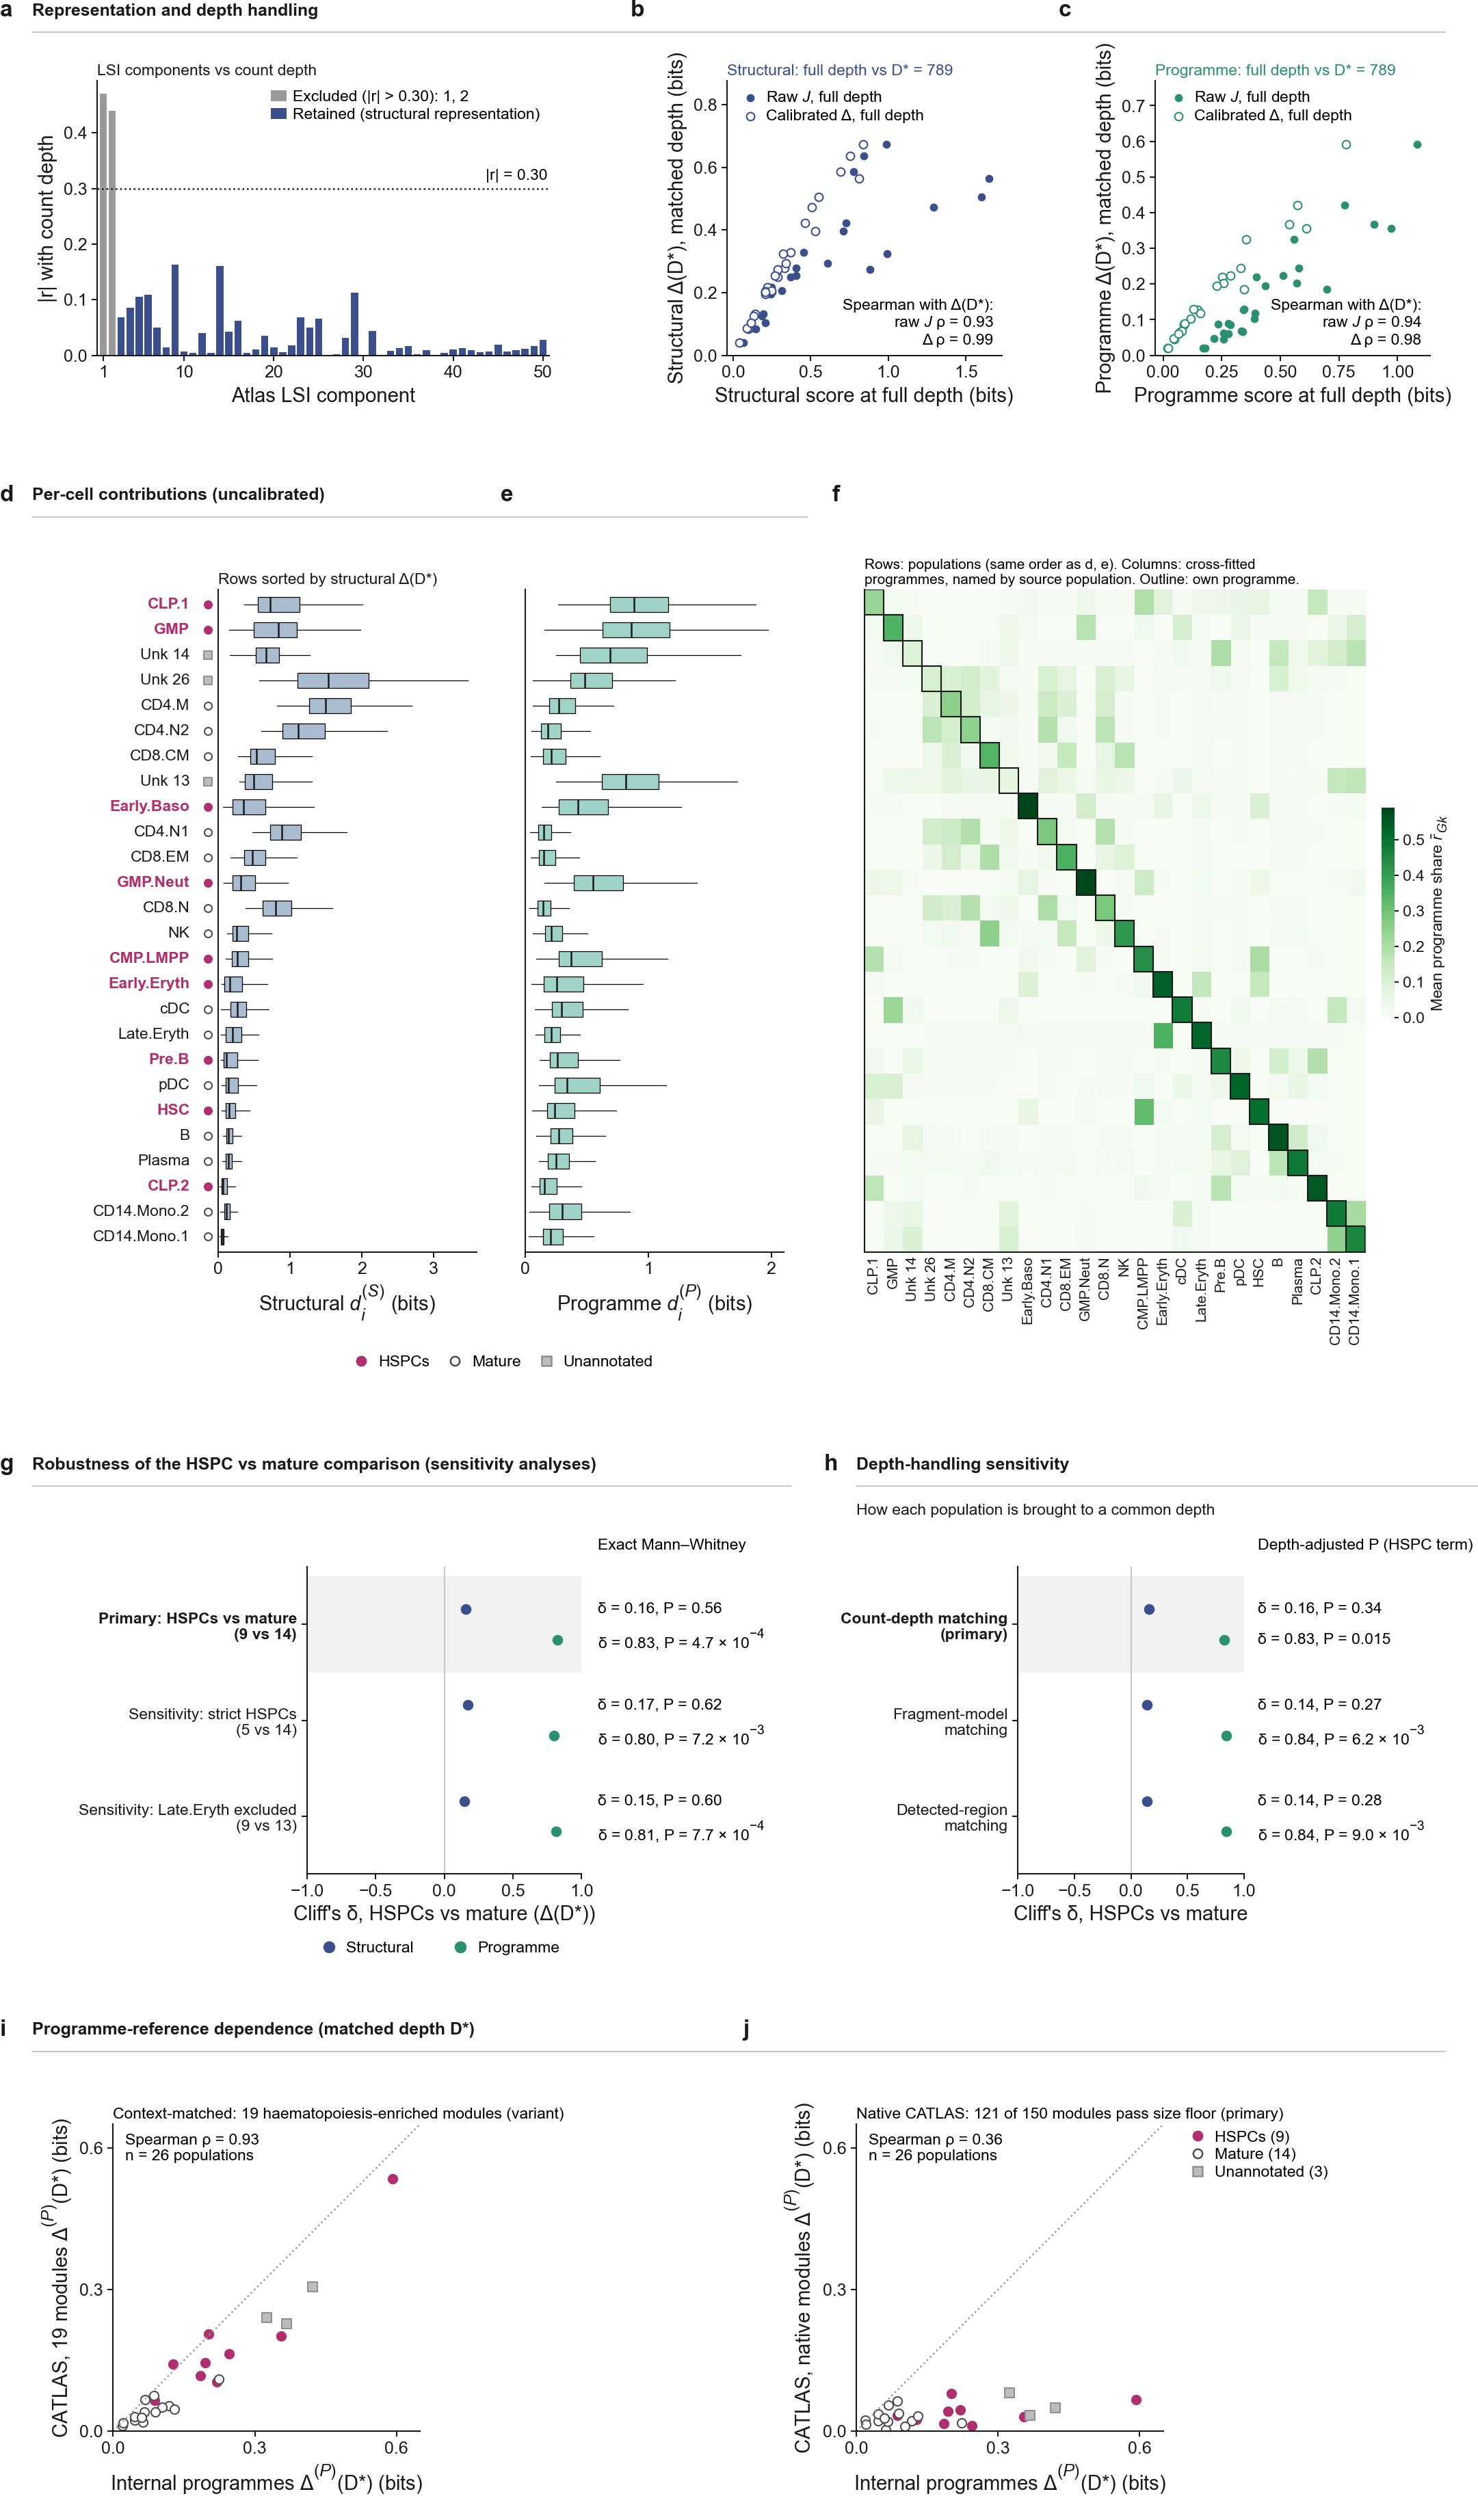

In [14]:
from IPython.display import display, Image
cv = build("FigureS4", SIZE, [('a',PANELS['a'][0],PANELS['a'][1],panel_a),('b',PANELS['b'][0],PANELS['b'][1],panel_b),('c',PANELS['c'][0],PANELS['c'][1],panel_c),('d',PANELS['d'][0],PANELS['d'][1],panel_d),('e',PANELS['e'][0],PANELS['e'][1],panel_e),('f',PANELS['f'][0],PANELS['f'][1],panel_f),('g',PANELS['g'][0],PANELS['g'][1],panel_g),('h',PANELS['h'][0],PANELS['h'][1],panel_h),('i',PANELS['i'][0],PANELS['i'][1],panel_i),('j',PANELS['j'][0],PANELS['j'][1],panel_j)])
display(Image(filename=str(OUTPUT_DIR / "FigureS4.png")))
plt.close(cv.fig)